In [4]:
from sae import load_sdxl_turbo_sae
from huggingface_hub import hf_hub_download
import torch

In [5]:
file_path = hf_hub_download(
    repo_id=f"Goodfire/SDXL-Turbo-SAE-ldown.attns.2.1",
    filename=f"SDXL-Turbo-SAE-ldown_blocks.2.attentions.1.pt",
    repo_type="model"
)
device = "cuda"
sae = load_sdxl_turbo_sae(file_path, device, dtype=torch.float32,)

In [17]:
sae.eval()

BatchTopKSAE(
  (encoder): Linear(in_features=1280, out_features=10240, bias=True)
  (decoder): Linear(in_features=10240, out_features=1280, bias=True)
)

In [18]:
from diffusers import DiffusionPipeline
from typing import Callable, Optional
from functools import partial


INTERVENTION_INTERFACE = Callable[[torch.Tensor, torch.Tensor], torch.Tensor]


class ObservableSdxlTurbo:
    def __init__(self):
        self._model = DiffusionPipeline.from_pretrained(
            "stabilityai/sdxl-turbo",
            torch_dtype=torch.float16,
        )
        self.d_model = 1280
    
    def _locate_block(self, position: str):
        block = self._model
        for step in position.split('.'):
            if step.isdigit():
                step = int(step)
                block = block[step]
            else:
                block = getattr(block, step)
        return block

    def generate(
        self,
        prompt: str,
        num_inference_steps: int = 3,
        guidance_scale: float = 0.0,
        interventions: Optional[dict[int, INTERVENTION_INTERFACE]] = None,
        **kwargs
    ) -> tuple[torch.Tensor, dict[str, torch.Tensor]]:
        if not interventions:
            interventions = {}

        layers = list(set(interventions.keys()))

        hooks = []
        if layers:
            for layer in layers:
                
                def _intervene(model, input, output, layer=None):
                    if layer in interventions:
                        acts = interventions[layer](input, output)
                    return acts
                
                hooks.append(
                    self._locate_block(layer).register_forward_hook(partial(_intervene, layer=layer))
                )

        # Run forwards pass
        try:
            print(f"Running with params: {prompt}, {num_inference_steps}, {guidance_scale}")
            output = self._model(
                prompt,
                num_inference_steps=num_inference_steps,
                guidance_scale=guidance_scale,
                **kwargs
            )
        finally:
            for hook in hooks:
                hook.remove()
                       
        return output.images[0]

        
model = ObservableSdxlTurbo()
model._model = model._model.to('cuda')

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Running with params: a cat, 1, 0.0


  0%|          | 0/1 [00:00<?, ?it/s]

shape of to_encode: torch.Size([1280, 256])
shape of to_encode: torch.Size([256, 1280])
encoded.
shape of img_reconstructed: torch.Size([256, 1280])


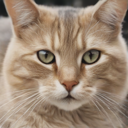

In [ ]:
def _sae_bottlenecked_inference(inputs, outputs): 
    to_encode = outputs[0].to(torch.float32).reshape(1280, -1)
    print(f"shape of to_encode: {to_encode.shape}")
    to_encode = to_encode.permute(1, 0)
    print(f"shape of to_encode: {to_encode.shape}")
    features = sae.encode(to_encode)
    print(f"encoded.")
    img_reconstructed = sae.decode(features)
    print(f"shape of img_reconstructed: {img_reconstructed.shape}")
    img_reconstructed = img_reconstructed.to(torch.float16).permute(1, 0).reshape(1, 1280, 16, 16)
    return (img_reconstructed, ) + outputs[1:]

interventions = {"unet.down_blocks.2.attentions.1": _sae_bottlenecked_inference}

image = model.generate(
    'a cat',
    interventions=interventions,
    num_inference_steps=1,
    generator=torch.Generator(
        device="cuda" if torch.cuda.is_available() else "cpu"
    ).manual_seed(42),
)
image.resize((128, 128))